In [1]:
import numpy as np 
import os
import matplotlib.pyplot as plt 
import math
import mdtraj as md
import seaborn as sns

In [9]:
coord_mm = np.load('1396156_coords_lam0.npz')['coords']
coord_ml = np.load('1396156_coords_lam1.npz')['coords']

coord_mm_lig = coord_mm[:,:14,:]
coord_ml_lig = coord_ml[:,:14,:]



In [10]:
topology = md.Topology()
chain = topology.add_chain()
residue = topology.add_residue("res", chain)
for i in range(14):
    topology.add_atom(f"Atom{i}", element=md.element.carbon, residue=residue)

In [11]:
phi1_ind = [[1,0,11,12]]

phi1 = []
for molecule in coord_mm_lig:
    traj = md.Trajectory(molecule, topology)
    dihedrals_1 = md.compute_dihedrals(traj, phi1_ind)[0][0]
    phi1.append(dihedrals_1)
    
phi1_MM = np.degrees(phi1)
phi1_MM = np.abs(phi1_MM)#symmetrical mol

phi1 = []
for molecule in coord_ml_lig:
    traj = md.Trajectory(molecule, topology)
    dihedrals_1 = md.compute_dihedrals(traj, phi1_ind)[0][0]
    phi1.append(dihedrals_1)
    
phi1_ML = np.degrees(phi1)

In [12]:
data_file = './output_1396156_tot_ener.txt'
angles = []
energies_hartree = []
with open(data_file, 'r') as f:
    for line in f:
        try:
            parts = line.strip().split()
            if len(parts) >= 2:
                angles.append(float(parts[0]))
                energies_hartree.append(float(parts[-1]))
        except ValueError:
            continue

angles = np.array(angles)
energies_hartree = np.array(energies_hartree)

min_energy = np.min(energies_hartree)
conversion_factor = 627.509 # 1 Hartree = 627.509 kcal/mol
rel_energies_kcal = (energies_hartree - min_energy) * conversion_factor

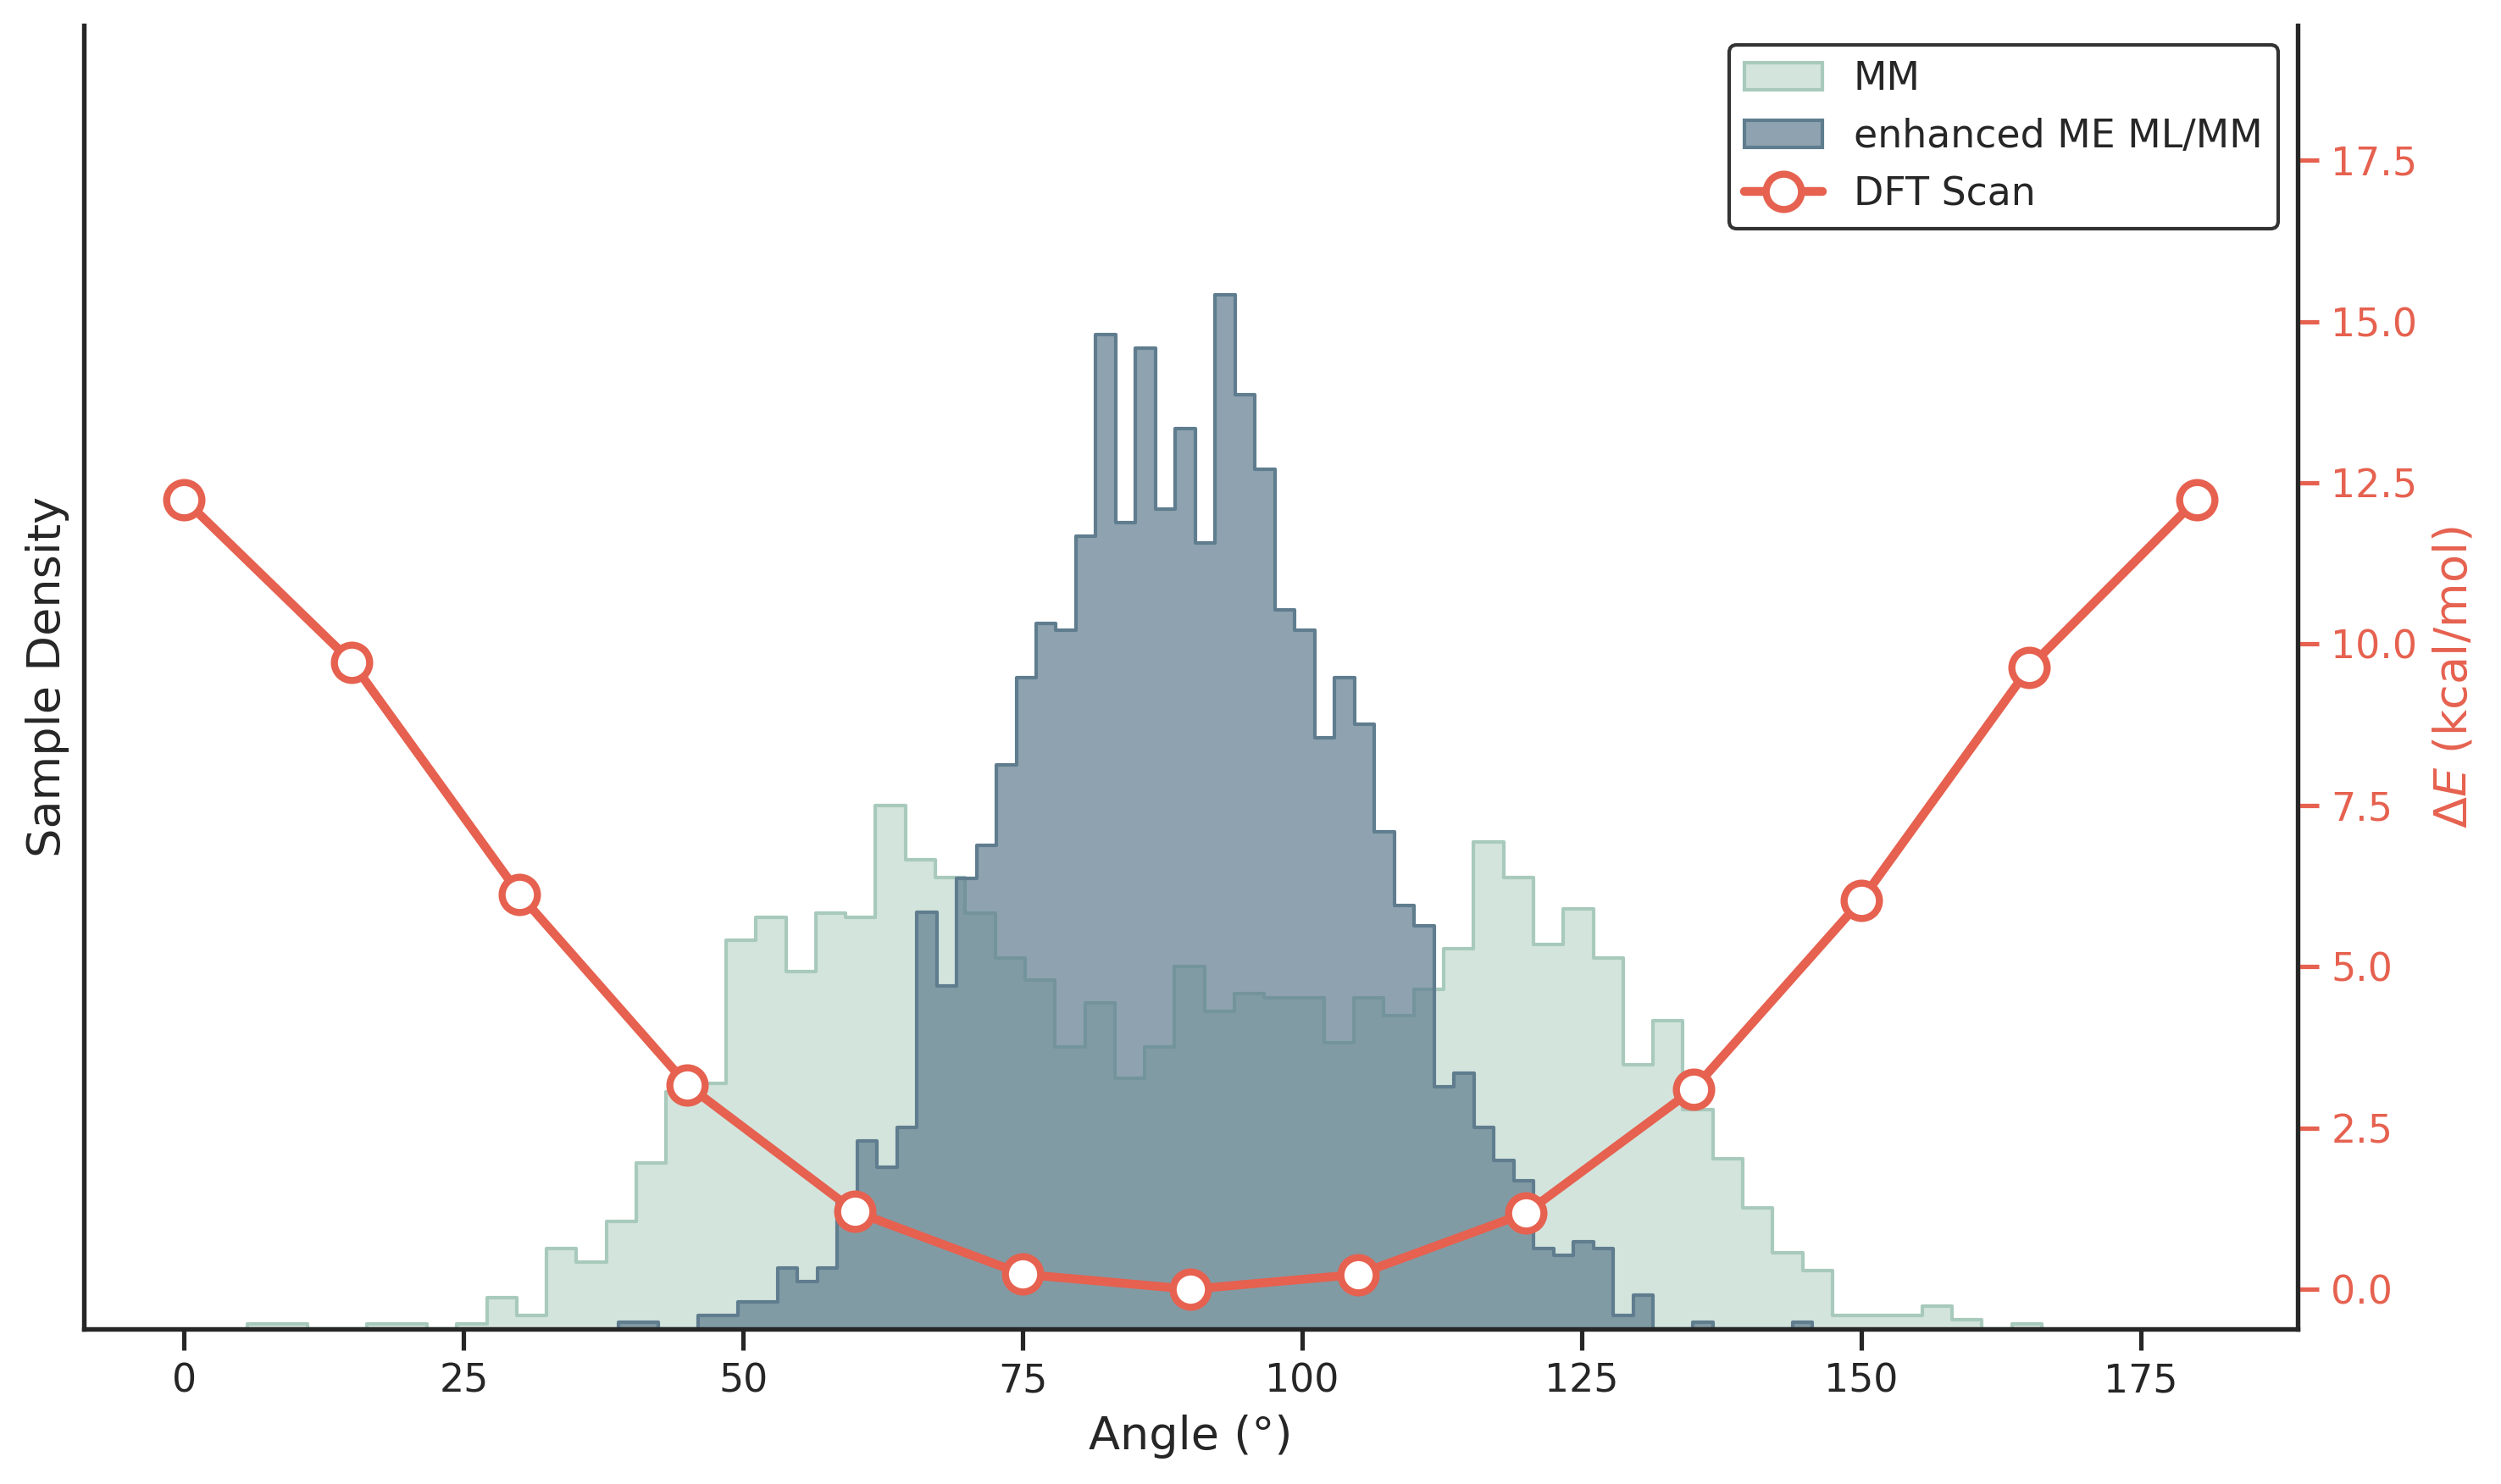

In [13]:
sns.set_theme(style="ticks")
fig, ax1 = plt.subplots(figsize=(10, 6), dpi=300)
sns.histplot(x=phi1_MM, stat="density", bins=60, element="step", fill=True, color="#A8CABC", alpha=0.5, label="MM", ax=ax1)
sns.histplot(x=phi1_ML, stat="density", bins=60, element="step", fill=True, color="#5F7D8E", alpha=0.7, label="enhanced ME ML/MM", ax=ax1)
ax1.set_xlabel('Angle (°)', fontsize=13, fontweight='medium')
ax1.set_ylabel('Sample Density', fontsize=13, fontweight='medium')
ax1.set_yticks([])
ax1.set_ylim(0, ax1.get_ylim()[1] * 1.2)
ax2 = ax1.twinx()

ax2.plot(angles, rel_energies_kcal, 
        marker='o', markersize=10, markerfacecolor='white', markeredgewidth=2, 
        linestyle='-', linewidth=2.5, 
        color='#E6614F', label='DFT Scan')

ax2.set_ylabel(r'$\Delta E$ (kcal/mol)', fontsize=13, color='#E6614F', fontweight='medium')
ax2.tick_params(axis='y', colors='#E6614F') 

y2_min, y2_max = ax2.get_ylim()
new_y2_max = y2_min + (y2_max - y2_min) * 1.5
ax2.set_ylim(y2_min, new_y2_max)

sns.despine(top=True, right=False, left=False, bottom=False)

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right', frameon=True, edgecolor='black', fontsize=11)



plt.tight_layout()
# plt.savefig('1396156_angle.svg', dpi=300)
plt.show()